# Freight rate prediction — exploratory data analysis

**Goal:** understand the data before modelling. For each finding, decide whether
the affected records are kept, transformed, imputed or excluded, and what that
means for the validation design.

**Data:**
- `data/train_test.csv`: labelled development data, 48,000 loads, Jan–Oct 2025
- `data/validation.csv`: 12,000 loads that need predictions
- `data/december_chart_inputs.csv`: the fixed lane used for the December chart

**Conventions:**
- **rpm** = rate per mile = `posted_rate / distance`.
- **expected rpm** = the median rpm of loads with the same equipment and
  distance decile.
- **rpm ratio** = rpm / expected rpm. A value of 1.0 means the load is priced
  like its peers. This is only an EDA reference, not a model.

Helpers live in `src/freight_rate/analysis/eda.py`. Figures are saved to
`reports/eda/figures/` for the report. The decision log is in
`docs/phase1_data_audit.md`.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from freight_rate.analysis import eda
from freight_rate.analysis import plotting as P
from freight_rate.config import load_config
from freight_rate.data import io, schema

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
P.apply_style()

cfg = load_config()
FIG_DIR = cfg.paths.eda_dir / "figures"


def save_fig(fig, name):
    """Save for the report and keep the figure displayed in the notebook."""
    P.save(fig, FIG_DIR / name, close=False)
    return fig

In [2]:
# Loaders validate columns, IDs, dates and equipment values (see src/freight_rate/data/io.py)
train = io.load_train(cfg.paths.train)
val = io.load_validation(cfg.paths.validation)
template = io.load_template(cfg.paths.validation_template)
december = io.load_december_inputs(cfg.paths.december_inputs)

print(f"train      {train.shape}")
print(f"validation {val.shape}")
print(f"template   {template.shape}")
print(f"december   {december.shape}")

train      (48000, 14)
validation (12000, 13)
template   (12000, 2)
december   (31, 7)


## 2. Dataset overview

What is the time coverage of each file, how many rows are there, and do the IDs
line up?

In [3]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.0912,-76.7891,38.1691,-72.7456,274.3000,Dry Van,"30,658.0000",2025-01-01,0.9568,2.3960,645.4100
1,TR-000002,Richmond,Philadelphia,38.0912,-76.7891,39.2232,-72.9671,280.5000,Reefer,"17,555.0000",2025-01-01,0.9762,2.4335,679.9700
2,TR-000003,Philadelphia,Green Bay,39.2232,-72.9671,44.3030,-87.5287,967.8000,Dry Van,"31,721.0000",2025-01-01,1.0097,1.8449,"1,802.5400"
3,TR-000004,Hartford,Atlanta,39.5533,-72.1805,34.8493,-86.2894,965.4000,Dry Van,"32,333.0000",2025-01-01,0.9452,1.8771,"1,827.2800"
4,TR-000005,Dallas,Nashville,31.8302,-94.3834,35.2948,-88.0892,541.9000,Reefer,"35,183.0000",2025-01-01,0.9848,2.5630,"1,380.2800"


In [4]:
def coverage(frame):
    return frame[schema.DATE].dt.to_period("M").value_counts().sort_index()

pd.concat({"train": coverage(train), "validation": coverage(val)}, axis=1).fillna(0).astype(int).T

date,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
train,4918,4337,5036,4819,4913,4783,4912,4759,4670,4853,0,0
validation,0,0,0,0,0,0,0,0,0,0,5836,6164


In [5]:
summary = pd.DataFrame(
    {
        "rows": [len(train), len(val)],
        "first date": [train.date.min().date(), val.date.min().date()],
        "last date": [train.date.max().date(), val.date.max().date()],
        "duplicate rows (ignoring load_id)": [
            train.drop(columns="load_id").duplicated().sum(),
            val.drop(columns="load_id").duplicated().sum(),
        ],
        "cities": [len(set(train.pickup) | set(train.delivery)), len(set(val.pickup) | set(val.delivery))],
    },
    index=["train", "validation"],
)
display(summary)

print("Template IDs identical to validation IDs, same order:",
      template.load_id.tolist() == val.load_id.tolist())
print("Equipment share:")
display(pd.concat({"train": train.equipment.value_counts(normalize=True),
                   "validation": val.equipment.value_counts(normalize=True)}, axis=1))

,rows,first date,last date,duplicate rows (ignoring load_id),cities
train,48000,2025-01-01,2025-10-31,0,64
validation,12000,2025-11-01,2025-12-31,0,72


Template IDs identical to validation IDs, same order: True
Equipment share:


,train,validation
equipment,,
Dry Van,0.5667,0.5650
Reefer,0.2509,0.2542
Flatbed,0.1824,0.1807


In [6]:
# The December chart file: only these columns, no market_index / quote_signal / coordinates
december.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,813.9806
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,820.7162
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,826.0667
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,829.4238
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,825.3140


**Findings**
- Training covers Jan–Oct 2025. Validation covers **Nov and Dec 2025**. The
  task is a **1–2 month ahead forecast**, so validation must be time-based.
- No duplicates. Template IDs match the validation IDs exactly.
- Validation contains 8 cities that never appear in training (section 10).
- The December chart file lacks `market_index`, `quote_signal` and coordinates
  (section 12).

## 3. Target and distance

How is `posted_rate` distributed, and what drives it?

In [7]:
df = eda.add_reference_columns(train)   # adds month, rpm, expected_rpm, rpm_ratio, label_anomaly, circuity
df[[schema.TARGET, "rpm", "distance"]].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
posted_rate,"48,000.0000","2,373.9807","1,486.4932",57.2200,327.1688,"2,030.7600","5,972.8340","25,533.0000"
rpm,"48,000.0000",2.2153,0.5839,0.3337,1.6735,2.1453,3.1769,14.1253
distance,"48,000.0000","1,135.8567",728.5644,70.0000,121.8990,953.3000,"3,029.3040","3,439.8000"


In [8]:
df[["distance", "weight", "market_index", "quote_signal", schema.TARGET]].corr()[schema.TARGET].to_frame("corr with posted_rate")

,corr with posted_rate
distance,0.9085
weight,0.0348
market_index,0.0342
quote_signal,-0.0399
posted_rate,1.0000


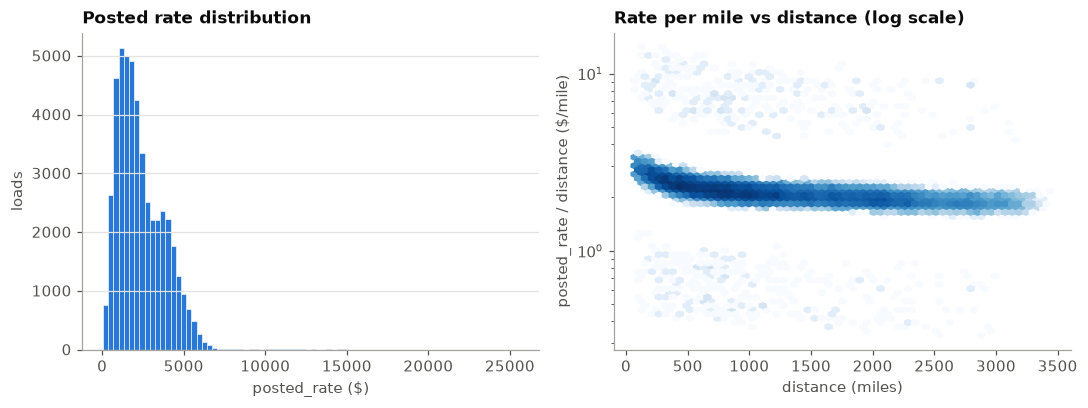

In [9]:
save_fig(eda.fig_target_vs_distance(df), "01_target_vs_distance.png");

**Findings**
- Distance is the dominant driver (correlation 0.91). Rate per mile falls as
  distance grows.
- The right-hand plot shows **three separate bands**: the main band at about
  $2/mile, plus a band far above and a band far below. Rates up to $25.5k on a
  $2k median also look suspicious. Section 4 investigates this.

## 4. Label anomalies

Compare each load's rate per mile with the median for its equipment and distance
decile. Real market variation should be continuous. Data errors should form
separate clusters.

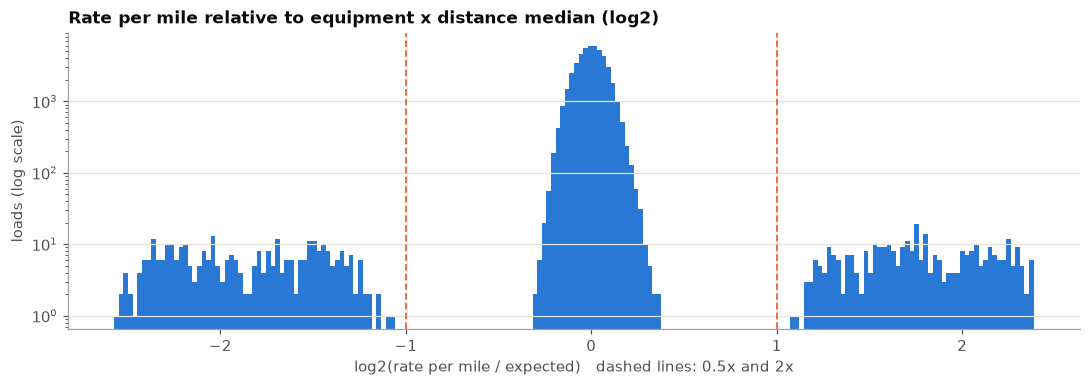

In [10]:
save_fig(eda.fig_anomaly_clusters(df), "02_label_anomaly_clusters.png");

In [11]:
ranges = df.groupby("label_anomaly")["rpm_ratio"].agg(["size", "min", "median", "max"])
ranges["share %"] = ranges["size"] / len(df) * 100
display(ranges)

# Is there anything between the clusters?
between = df.rpm_ratio.between(0.48, 0.81) | df.rpm_ratio.between(1.29, 2.12)
print("Rows with ratio in the gaps (0.48-0.81 or 1.29-2.12):", between.sum())

,size,min,median,max,share %
label_anomaly,,,,,
high,340,2.1303,3.3726,5.2249,0.7083
low,337,0.1682,0.2773,0.4743,0.7021
normal,47323,0.8136,1.0000,1.2839,98.5896


Rows with ratio in the gaps (0.48-0.81 or 1.29-2.12): 0


In [12]:
# Are anomalies concentrated anywhere? (month, equipment)
is_anom = df.label_anomaly != "normal"
display(is_anom.groupby(df.month).mean().mul(100).round(2).to_frame("anomaly % by month").T)
display(is_anom.groupby(df.equipment).mean().mul(100).round(2).to_frame("anomaly % by equipment").T)

month,1,2,3,4,5,6,7,8,9,10
anomaly % by month,1.6500,1.3100,1.4100,1.3700,1.2600,1.3200,1.3200,1.4300,1.3700,1.6500


equipment,Dry Van,Flatbed,Reefer
anomaly % by equipment,1.3500,1.4500,1.5100


In [13]:
# Do anomalies coincide with other data issues?
anom = df[is_anom]
pd.Series({
    "anomalous rows": len(anom),
    "also negative weight": (anom.weight < 0).sum(),
    "also missing weight": anom.weight.isna().sum(),
    "also missing market_index": anom.market_index.isna().sum(),
    "median circuity (normal ≈ 1.18)": round(anom.circuity.median(), 3),
}).to_frame("count")

,count
anomalous rows,677.0000
also negative weight,9.0000
also missing weight,3.0000
also missing market_index,6.0000
median circuity (normal ≈ 1.18),1.1830


In [14]:
anom.sort_values("rpm_ratio")[["load_id", "pickup", "delivery", "distance", "equipment",
                               "posted_rate", "rpm", "expected_rpm", "rpm_ratio"]].iloc[[0, 1, 2, -3, -2, -1]]

,load_id,pickup,delivery,distance,equipment,posted_rate,rpm,expected_rpm,rpm_ratio
45059,TR-045060,Raleigh,Columbia,420.9000,Reefer,183.7700,0.4366,2.5958,0.1682
2511,TR-002512,Buffalo,San Antonio,"1,644.3000",Flatbed,596.0400,0.3625,2.0991,0.1727
508,TR-000509,Las Vegas,Grand Rapids,"1,976.4000",Flatbed,699.4100,0.3539,2.0405,0.1734
28012,TR-028013,Montgomery,Houston,604.3000,Reefer,"7,773.3700",12.8634,2.4750,5.1974
27969,TR-027970,Buffalo,Boston,589.9000,Reefer,"7,597.5200",12.8793,2.4750,5.2039
40096,TR-040097,Baltimore,Oklahoma City,"1,760.3000",Reefer,"20,132.3700",11.4369,2.1889,5.2249


**Findings**
- **1.41% of training labels (677 rows) fall in two clusters:** 0.17–0.47× and
  2.13–5.23× the expected rate per mile. Clean loads sit in a tight band
  (0.81–1.28×), and **no load falls between the clusters.**
- Anomalies are spread evenly over months and equipment. They don't line up
  with other data issues. They look like corrupted labels, not real market
  prices.

**Decision:** treat these as label noise. Exclude them when fitting models, with
the flag computed inside each training fold only. Keep them in evaluation, and
report metrics on all rows and on clean rows.

## 5. How much do anomalies affect the metrics?

Simple baseline: predict the training-window median rate per mile for the
load's equipment × distance bin, times its distance. Train on Jan–Aug and test
on Sep–Oct, which mimics the 2-month forecast horizon.

In [15]:
impact = eda.outlier_impact(df)
impact

,training,evaluated on,rows,MAE,RMSE,median AE,MAPE %,total abs error
0,train on all rows,all holdout rows,9523,134.9500,638.4900,58.6200,6.1900,"1,285,127.6200"
1,train on all rows,clean rows,9379,79.3200,108.6800,57.2400,3.6800,"743,895.8000"
2,train on all rows,anomalous rows,144,"3,758.5500","5,117.7200","2,507.6300",169.9300,"541,231.8200"
3,train excluding anomalies,all holdout rows,9523,134.9100,638.4900,58.5400,6.1900,"1,284,788.7900"
4,train excluding anomalies,clean rows,9379,79.2800,108.5800,57.1800,3.6800,"743,539.0600"
5,train excluding anomalies,anomalous rows,144,"3,758.6800","5,117.8000","2,507.5400",169.9400,"541,249.7400"


In [16]:
base = impact[impact.training == "train on all rows"].set_index("evaluated on")
share = base.loc["anomalous rows", "total abs error"] / base.loc["all holdout rows", "total abs error"]
print(f"Anomalous rows are {base.loc['anomalous rows', 'rows'] / base.loc['all holdout rows', 'rows']:.1%} "
      f"of the holdout but produce {share:.0%} of its total absolute error.")

Anomalous rows are 1.5% of the holdout but produce 42% of its total absolute error.

**Findings**
- About 1.5% of holdout rows produce about 42% of the absolute error. The
  holdout MAE is about $135 on all rows vs $79 on clean rows, and the RMSE is
  6× larger.
- For a **median-based** baseline, excluding anomalies barely changes the
  result: medians are already robust. Mean-based learners (squared loss) would
  be pulled by them. That comparison is repeated with real models in Phase 4.
- The validation set probably contains about 1.5% such rows as well. Nobody can
  predict them, so the aim is to predict the true rate well.

## 6. Equipment and distance

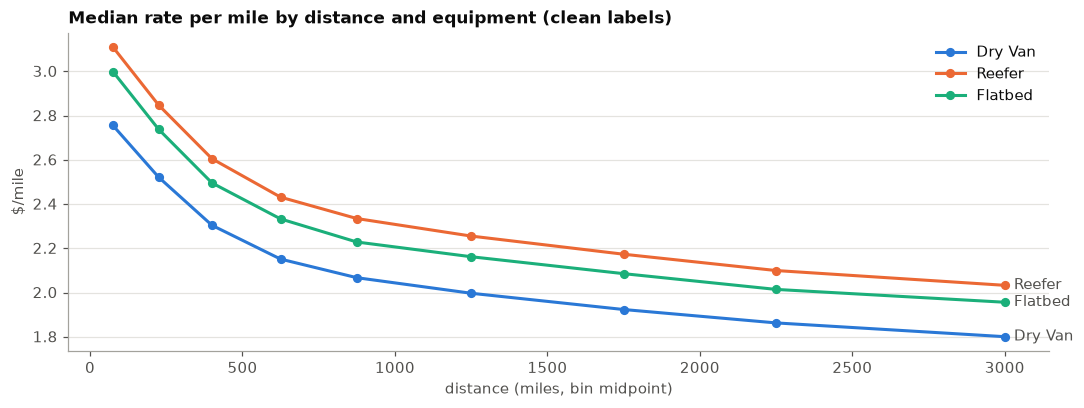

In [17]:
save_fig(eda.fig_rpm_by_equipment_distance(df), "04_rpm_by_equipment_distance.png");

In [18]:
clean = df[df.label_anomaly == "normal"]
clean.groupby("equipment")[[schema.TARGET, "rpm"]].median()

,posted_rate,rpm
equipment,,
Dry Van,"1,952.5500",2.0458
Flatbed,"2,078.5900",2.2197
Reefer,"2,202.2800",2.3120


**Findings**
- Each equipment type shifts the whole rate-per-mile curve: Reefer is highest,
  then Flatbed, then Dry Van. The curves are roughly parallel.
- Rate per mile decreases non-linearly with distance. Modelling log(rate) with
  log(distance), or using a tree model, captures this naturally.

## 7. Weight

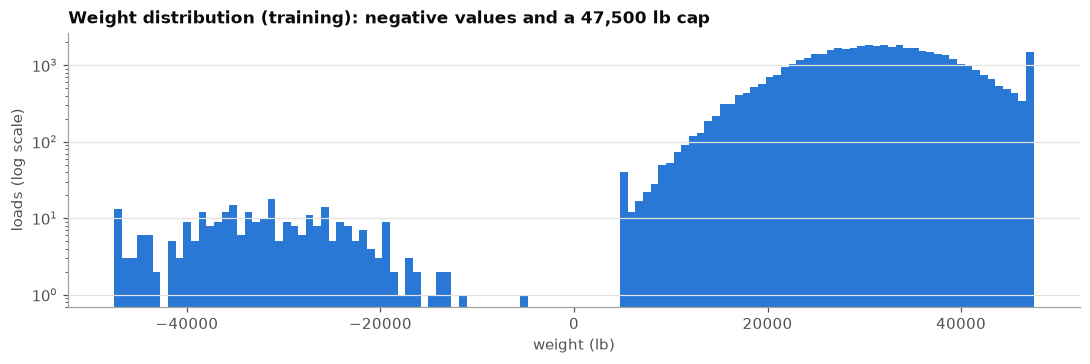

In [19]:
save_fig(eda.fig_weight_distribution(train), "05_weight_distribution.png");

In [20]:
w = train.weight
pd.Series({
    "negative (train)": (w < 0).sum(),
    "negative (validation)": (val.weight < 0).sum(),
    "exactly 47,500 (train)": np.isclose(w, eda.WEIGHT_CAP).sum(),
    "exactly -47,500 (train)": np.isclose(w, -eda.WEIGHT_CAP).sum(),
    "exactly 47,500 (validation)": np.isclose(val.weight, eda.WEIGHT_CAP).sum(),
    "smallest positive": w[w > 0].min(),
}).to_frame("value")

,value
negative (train),292.0000
negative (validation),145.0000
"exactly 47,500 (train)","1,191.0000"
"exactly -47,500 (train)",13.0000
"exactly 47,500 (validation)",297.0000
smallest positive,"5,000.0000"


In [21]:
# If negative weights are sign errors, their absolute values should look like the positive weights
q = [0.05, 0.25, 0.5, 0.75, 0.95]
pd.DataFrame({"|negative weights|": w[w < 0].abs().quantile(q),
              "positive weights": w[w > 0].quantile(q)}).T.round(0)

,0.0500,0.2500,0.5000,0.7500,0.9500
|negative weights|,"18,966.0000","25,928.0000","31,822.0000","37,284.0000","46,070.0000"
positive weights,"18,004.0000","25,922.0000","31,494.0000","37,063.0000","44,962.0000"


In [22]:
# ...and they should be priced like comparable loads
df.groupby(np.sign(df.weight))["rpm_ratio"].median().rename({-1.0: "negative", 1.0: "positive"}).to_frame("median rpm ratio")

,median rpm ratio
weight,
negative,1.0024
positive,1.0000


In [23]:
# Does weight affect price? (clean rows, absolute weight)
cw = clean.dropna(subset=["weight"])
cw.groupby(pd.qcut(cw.weight.abs(), 5), observed=True)["rpm_ratio"].median().to_frame("median rpm ratio by |weight| quintile")

,median rpm ratio by |weight| quintile
weight,
"(4999.999, 24598.0]",0.9646
"(24598.0, 29388.0]",0.9829
"(29388.0, 33611.0]",1.0022
"(33611.0, 38413.0]",1.0203
"(38413.0, 47500.0]",1.0313


**Findings and decisions**
- 292 training and 145 validation weights are negative. Their absolute values
  match the positive distribution and they are priced normally. **Sign error →
  use the absolute value.**
- About 2.5% of loads sit exactly at 47,500 lb, a cap. **Keep as is.**
- Heavier loads cost more: about 7% between the lightest and heaviest fifths. A
  useful secondary feature.

## 8. Missing values

In [24]:
pd.DataFrame({"train missing": train.isna().sum(), "validation missing": val.isna().sum()}).query("`train missing` > 0 or `validation missing` > 0")

,train missing,validation missing
market_index,374,249.0000
weight,300,165.0000


In [25]:
both = pd.concat([train.assign(split="train"), val.assign(split="validation")])
(both.groupby(both.date.dt.to_period("M"))[["weight", "market_index"]]
     .apply(lambda g: g.isna().mean() * 100).round(2).T)

date,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
weight,0.6900,0.7600,0.7100,0.4200,0.4500,0.6700,0.5900,0.6100,0.7100,0.6600,1.4100,1.3500
market_index,0.7300,0.8300,0.8700,0.6400,0.8800,0.8800,0.7300,0.6900,0.6600,0.8700,1.9700,2.1700


In [26]:
# Is missingness related to price? (median rpm ratio when missing vs present)
pd.DataFrame({col: df.groupby(df[col].isna())["rpm_ratio"].median() for col in ["weight", "market_index"]}).rename(index={False: "present", True: "missing"})

,weight,market_index
present,1.0000,1.0000
missing,0.9992,0.9949


**Findings and decisions**
- Only `weight` and `market_index` have gaps: under 1% in training, about 1.4–2%
  in validation.
- Missingness is unrelated to price. The rpm ratio is the same whether the
  value is missing or present.
- **weight:** fill with the training-fold median, plus a missing-value flag (or
  the model's native missing handling).
- **market_index:** fill with the **same day's mean** (section 9 shows it's a
  daily market value). This uses no labels, so there's no leakage.

## 9. Market signals and time

`market_index` and `quote_signal`: are they per-load or market-wide, and do they
explain price changes over time?

In [27]:
def spread(frame, col):
    g = frame.groupby(schema.DATE)[col]
    return pd.Series({"std within a day (avg)": g.std().mean(), "std of daily means": g.mean().std()})

pd.DataFrame({"market_index": spread(train, "market_index"), "quote_signal": spread(train, "quote_signal")})

,market_index,quote_signal
std within a day (avg),0.0249,0.2606
std of daily means,0.1665,0.1294


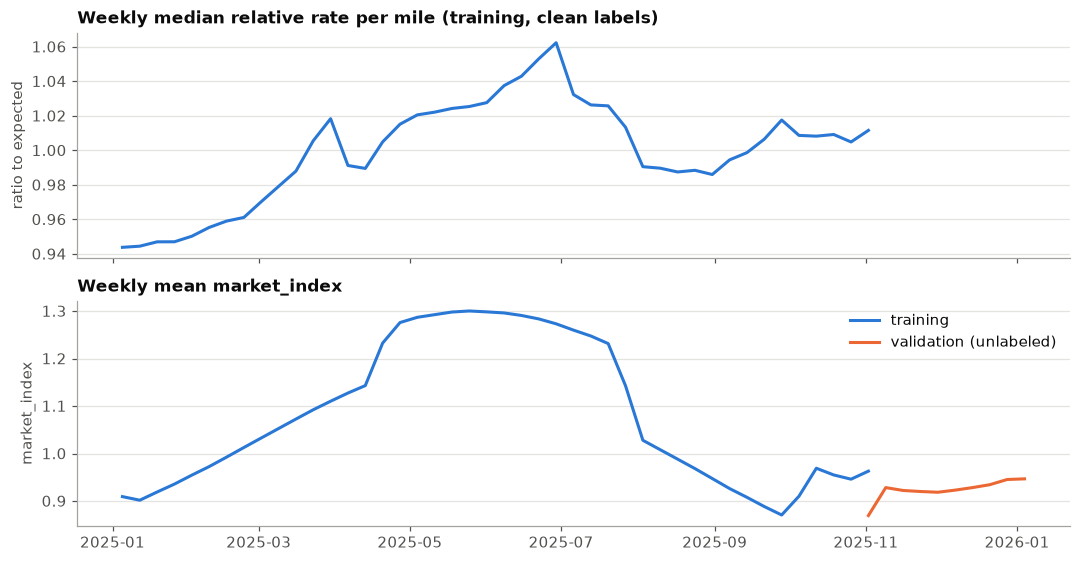

In [28]:
save_fig(eda.fig_market_over_time(df, val), "03_market_over_time.png");

In [29]:
log_ratio = np.log(clean.rpm_ratio)
ok = clean.market_index.notna()
day_mean = lambda s: s.groupby(clean[schema.DATE]).transform("mean")

pd.Series({
    "row: log rpm ratio vs market_index": np.corrcoef(log_ratio[ok], clean.market_index[ok])[0, 1],
    "row: log rpm ratio vs quote_signal": np.corrcoef(log_ratio, clean.quote_signal)[0, 1],
    "within a day: rpm deviation vs market_index deviation":
        np.corrcoef((log_ratio - day_mean(log_ratio))[ok], (clean.market_index - day_mean(clean.market_index))[ok])[0, 1],
    "within a day: rpm deviation vs quote_signal deviation":
        np.corrcoef(log_ratio - day_mean(log_ratio), clean.quote_signal - day_mean(clean.quote_signal))[0, 1],
}).to_frame("correlation").round(3)

,correlation
row: log rpm ratio vs market_index,0.4170
row: log rpm ratio vs quote_signal,0.0730
within a day: rpm deviation vs market_index deviation,0.0820
within a day: rpm deviation vs quote_signal deviation,0.0720


In [30]:
# Does market_index explain the time pattern fully? Compare months at the SAME market_index level.
band = clean[clean.market_index.between(0.88, 0.97)]
band.groupby("month")["rpm_ratio"].agg(["median", "size"]).query("size > 100").T

month,1,2,3,7,8,9,10
median,0.9462,0.9526,0.9668,0.9795,0.9780,1.0079,1.0027
size,"1,542.0000","1,483.0000",478.0000,227.0000,"1,615.0000","1,456.0000","1,757.0000"


In [31]:
# Market level in validation vs training
pd.concat({"train": train.groupby(train.date.dt.month).market_index.mean(),
           "validation": val.groupby(val.date.dt.month).market_index.mean()}).to_frame("mean market_index").T

train                                                                validation       
date                  1      2      3      4      5      6      7      8      9      10         11     12
mean market_index 0.9267 0.9960 1.0729 1.2076 1.3015 1.2803 1.2009 0.9815 0.8930 0.9575     0.9187 0.9347

In [32]:
# Day-of-week effect
clean.groupby(clean.date.dt.day_name())["rpm_ratio"].median().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).to_frame("median rpm ratio").T

date,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
median rpm ratio,0.9915,0.9983,1.0083,1.0106,1.0071,0.9954,0.9889


**Findings**
- **`market_index` is a market-wide daily value.** It barely varies within a day
  (std 0.025) but moves a lot across the year (std 0.17), peaking May–July. It
  correlates 0.42 with relative price.
- **Prices drift beyond what `market_index` explains.** At the same index level
  (0.88–0.97), the rpm ratio is about 0.95 in Jan–Feb but about 1.00 in Sep–Oct,
  roughly 6% higher. So **the most recent months best represent Nov–Dec**, and
  a model must be judged on how well it forecasts *forward in time*.
- Validation market_index (about 0.92–0.93) lies inside the training range,
  close to the Jan/Sep/Oct levels. No extrapolation in that feature.
- **`quote_signal` looks weak when pooled** (correlation about 0.07), but that
  hides a month-by-month inversion. See section 9b.
- Day-of-week effects are within ±1%: negligible.

## 9b. `quote_signal`: a relationship that flips sign by month

The pooled correlation above (0.07) is misleading. This section checks the
relationship **within each month**. It was added after the first submission
draft, once the monthly inversion was pointed out in review.

In [33]:
# Within each month: rank correlation between quote_signal and rate per mile (all rows)
monthly = df.groupby("month").apply(
    lambda g: pd.Series({
        "Spearman(qs, rpm)": g[["quote_signal", "rpm"]].corr("spearman").iloc[0, 1],
        "Pearson(qs, rpm), clean rows": g.loc[g.label_anomaly == "normal", ["quote_signal", "rpm"]].corr().iloc[0, 1],
    }), include_groups=False)
monthly.round(3).T

month,1,2,3,4,5,6,7,8,9,10
"Spearman(qs, rpm)",0.9630,0.9650,0.9700,-0.9630,-0.9680,0.9680,-0.9650,-0.0220,0.9670,-0.9590
"Pearson(qs, rpm), clean rows",0.9960,0.9960,0.9970,-0.9930,-0.9940,0.9970,-0.9940,-0.0200,0.9970,-0.9940


In [34]:
# Inside a regime, quote_signal is an almost exact linear encoding of the true rate per mile
fits = []
for m, g in clean.groupby("month"):
    b, a = np.polyfit(g.quote_signal, g.rpm, 1)
    r2 = 1 - (g.rpm - (a + b * g.quote_signal)).var() / g.rpm.var()
    fits.append({"month": m, "intercept": a, "slope": b, "R2": r2})
pd.DataFrame(fits).set_index("month").round(3).T

month,1,2,3,4,5,6,7,8,9,10
intercept,0.0160,0.0150,0.0170,4.1210,4.1260,0.0110,4.1280,2.2110,0.0130,4.1320
slope,0.9920,0.9930,0.9920,-0.9850,-0.9880,0.9950,-0.9890,-0.0240,0.9940,-0.9900
R2,0.9920,0.9920,0.9930,0.9860,0.9880,0.9940,0.9870,0.0000,0.9940,0.9880


In [35]:
# Regime boundaries: the sign switches exactly at calendar-month boundaries
daily = clean.groupby("date").apply(lambda g: np.corrcoef(g.quote_signal, g.rpm)[0, 1], include_groups=False)
sign = np.sign(daily.round(1))
runs = (sign != sign.shift()).cumsum()
blocks = daily.groupby(runs).agg(start=lambda s: s.index.min().date(), end=lambda s: s.index.max().date(),
                                 days="size", mean_corr="mean")
blocks[blocks.days >= 5].round(2)   # August (no regime) breaks into many short noise runs, hidden here

,start,end,days,mean_corr
1,2025-01-01,2025-03-31,90,1.0000
2,2025-04-01,2025-05-31,61,-0.9900
3,2025-06-01,2025-06-30,30,1.0000
4,2025-07-01,2025-08-01,32,-0.9600
21,2025-09-01,2025-09-30,30,1.0000
22,2025-10-01,2025-10-31,31,-0.9900


In [36]:
# Label-free regime check: correlate quote_signal with the rate per mile EXPECTED from
# distance and equipment alone. Needs no labels, so it also works on validation data.
from freight_rate.data.quality import quote_signal_regimes

pd.concat({"training": quote_signal_regimes(train, train).set_index("period"),
           "validation": quote_signal_regimes(train, val).set_index("period")}).round(3)

loads  label_free_corr  labelled_corr    regime
           period                                                  
training   2025-01   4918           0.9220         0.4470  positive
           2025-02   4337           0.9180         0.4790  positive
           2025-03   5036           0.9130         0.4860  positive
           2025-04   4819          -0.9120        -0.4720  inverted
           2025-05   4913          -0.9160        -0.4590  inverted
           2025-06   4783           0.9210         0.4770  positive
           2025-07   4912          -0.9100        -0.4680  inverted
           2025-08   4759          -0.0170        -0.0140      none
           2025-09   4670           0.9210         0.4810  positive
           2025-10   4853          -0.9110        -0.4340  inverted
validation 2025-11   5836          -0.0040            NaN      none
           2025-12   6164          -0.0160            NaN      none

In [37]:
# Validation quote_signal looks exactly like August's no-regime noise
def qs_profile(frame):
    return pd.Series({"mean": frame.quote_signal.mean(), "std": frame.quote_signal.std(),
                      "skew": frame.quote_signal.skew(),
                      "corr with log distance": np.corrcoef(frame.quote_signal, np.log(frame.distance))[0, 1]})

pd.DataFrame({
    "Aug 2-31 (no regime)": qs_profile(train[(train.date >= "2025-08-02") & (train.date.dt.month == 8)]),
    "Oct (inverted)": qs_profile(train[train.date.dt.month == 10]),
    "Nov (validation)": qs_profile(val[val.date.dt.month == 11]),
    "Dec (validation)": qs_profile(val[val.date.dt.month == 12]),
}).round(3)

,Aug 2-31 (no regime),Oct (inverted),Nov (validation),Dec (validation)
mean,2.0520,1.9430,2.0550,2.0480
std,0.2220,0.2690,0.2200,0.2190
skew,-0.0150,-0.9420,-0.0080,0.0070
corr with log distance,0.0170,0.8210,0.0090,0.0130


**Findings and decision**
- **Within a month, `quote_signal` almost exactly encodes the true rate per
  mile** (rank correlation about ±0.96, R² about 0.99 on clean rows).
  - Positive months (Jan–Mar, Jun, Sep): rate per mile ≈ `quote_signal`.
  - Inverted months (Apr–May, Jul, Oct): rate per mile ≈ 4.13 − `quote_signal`.
  - **2–31 August: no relationship.**
- **The label-free check is reliable** (it matches the labelled regime in every
  month). It shows **no regime in Nov or Dec**, and validation `quote_signal`
  has August's distribution exactly.
- **So it can't be "handled" by flipping its sign.** In the forecast period it
  carries no information, and a model that uses it reads noise as price.
- **Decision: `quote_signal` is not used by the final model.** The
  deployment-like test (train through July, test 2–31 Aug) shows the selected
  model's clean MAE improves by about 12% without it
  (`python -m freight_rate.pipelines.quote_signal_check`).

## 10. Distance quality and geography

Does the stated distance agree with the coordinates?

In [38]:
df.circuity.describe(percentiles=[0.01, 0.5, 0.99]).to_frame("stated distance / great-circle distance").T

,count,mean,std,min,1%,50%,99%,max
stated distance / great-circle distance,"48,000.0000",1.1947,0.1435,1.0581,1.1296,1.1822,1.4039,9.6349


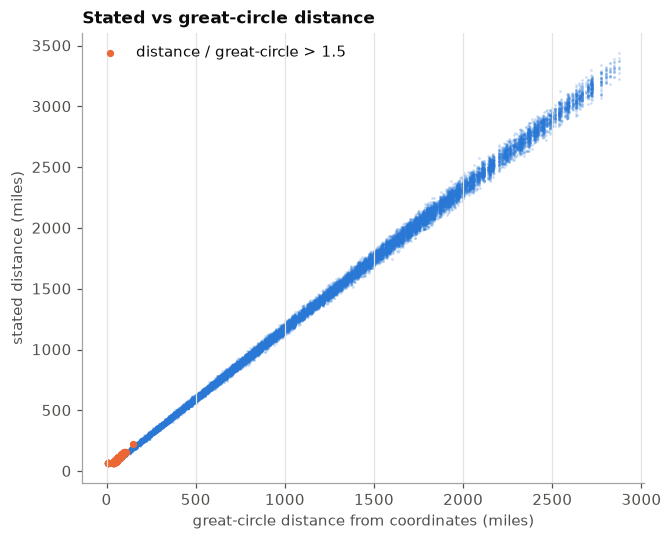

In [39]:
save_fig(eda.fig_distance_vs_haversine(df), "06_distance_vs_haversine.png");

In [40]:
# For loads with circuity > 1.5: is the price consistent with the stated distance or the geographic one?
odd = df[(df.circuity > 1.5) | (df.circuity < 1.0)]
typical = df.loc[df.circuity.between(1.0, 1.5), "circuity"].median()
print("rows:", len(odd), "| max stated distance among them:", odd.distance.max())
print("median rpm ratio using stated distance:    ", round(odd.rpm_ratio.median(), 3))
print("median rpm ratio using geographic distance:", round(((odd.posted_rate / (odd.haversine * typical)) / odd.expected_rpm).median(), 3))
print("loads at exactly 70 miles (train / validation):", (train.distance == 70).sum(), "/", (val.distance == 70).sum(),
      "| next smallest:", train.distance[train.distance > 70].min())

rows: 214 | max stated distance among them: 224.5
median rpm ratio using stated distance:     1.108
median rpm ratio using geographic distance: 1.519
loads at exactly 70 miles (train / validation): 48 / 21 | next smallest: 70.5


**Findings**
- Stated distance is usually about 1.18× the great-circle distance. The 214
  rows above 1.5× are all **short hauls**, and their prices match the *stated*
  distance. **Keep the stated distance.**
- There's a 70-mile floor (48 rows) with the next value at 70.5. Plausible;
  keep.

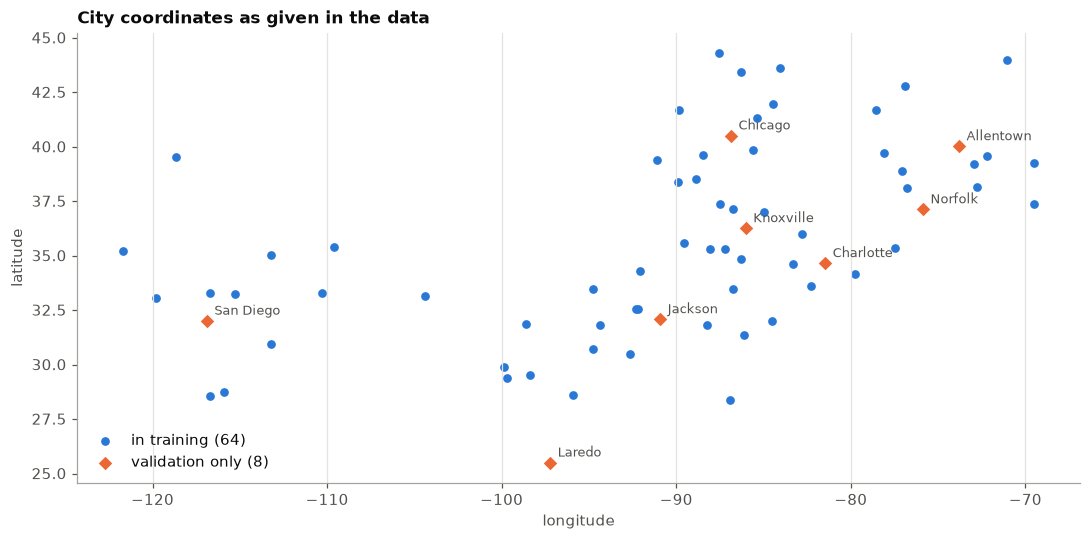

In [41]:
save_fig(eda.fig_city_coverage(train, val), "07_city_coverage.png");

In [42]:
train_cities = set(train.pickup) | set(train.delivery)
unseen = sorted((set(val.pickup) | set(val.delivery)) - train_cities)
touches_unseen = val.pickup.isin(unseen) | val.delivery.isin(unseen)
train_lanes = set(zip(train.pickup, train.delivery))
unseen_lane = ~pd.Series([lane in train_lanes for lane in zip(val.pickup, val.delivery)])

print("Unseen cities:", unseen)
print("Validation rows touching an unseen city:", touches_unseen.sum(), f"({touches_unseen.mean():.1%})")
print("Validation rows on an unseen lane between KNOWN cities:", (unseen_lane & ~touches_unseen.values).sum())

Unseen cities: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation rows touching an unseen city: 1447 (12.1%)
Validation rows on an unseen lane between KNOWN cities: 14


In [43]:
# How much does the origin / destination city matter once distance and equipment are known?
origin = np.log(clean.rpm_ratio).groupby(clean.pickup).median().sort_values()
dest = np.log(clean.rpm_ratio).groupby(clean.delivery).median().sort_values()
print(f"std of city effect (log): origin {origin.std():.4f}, destination {dest.std():.4f}")
pd.concat({"origin": origin.iloc[[0, 1, 2, -3, -2, -1]], "destination": dest.iloc[[0, 1, 2, -3, -2, -1]]}, axis=1).round(3)

std of city effect (log): origin 0.0165, destination 0.0164


,origin,destination
Syracuse,-0.0370,-0.0350
Buffalo,-0.0300,-0.0300
Albany,-0.0290,-0.0340
Dallas,0.0270,NaN
Oklahoma City,0.0270,0.0280
Lubbock,0.0280,NaN
Houston,NaN,0.0270
Tulsa,NaN,0.0270


In [44]:
# Coordinates look clipped to a bounding box
pd.Series({
    "train rows with lon exactly -69.5": ((train.pickup_lon == -69.5) | (train.delivery_lon == -69.5)).sum(),
    "validation rows with lat exactly 25.5": ((val.pickup_lat == 25.5) | (val.delivery_lat == 25.5)).sum(),
    "max distinct coordinates per city": train.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().max().max(),
}).to_frame("value")

,value
train rows with lon exactly -69.5,2052
validation rows with lat exactly 25.5,195
max distinct coordinates per city,1


**Findings**
- 8 cities appear only in validation (Allentown, Charlotte, Chicago, Jackson,
  Knoxville, Laredo, Norfolk, San Diego), affecting **12% of validation rows.**
  A model keyed on city names can't handle them.
- City effects are small (about 1.6% std) with a mild regional pattern (Upstate
  NY cheaper, TX/OK dearer). Coordinates can capture this smoothly, and they
  exist for unseen cities too.
- Coordinates are approximate and clipped (e.g. Laredo's latitude is exactly
  25.5). Use them only as rough regional features.
- Phase 2 will add a **held-out-cities** check to measure how the model handles
  new cities.

## 11. Train vs validation feature shift

In [45]:
q = [0.1, 0.5, 0.9]
pd.concat({col: pd.DataFrame({"train": train[col].quantile(q), "validation": val[col].quantile(q)}).T
           for col in ["distance", "weight", "market_index", "quote_signal"]}).round(3)

0.1000      0.5000      0.9000
distance     train         328.2000    953.3000  2,216.2100
             validation    328.3000    953.6000  2,225.1700
weight       train      20,831.8000 31,436.5000 41,886.0000
             validation 20,404.6000 31,193.0000 41,726.6000
market_index train           0.8710      1.0560      1.3330
             validation      0.8290      0.9230      1.0250
quote_signal train           1.7350      2.0560      2.4030
             validation      1.7730      2.0510      2.3350

Distance, weight, equipment and `quote_signal` distributions match. Only
`market_index` is lower in validation, and it stays inside the training range.
The main unvalidated risk is the **time trend** from section 9.

## 12. The December chart lane

The chart predicts Lexington → Fort Wayne, 360 mi, Dry Van, 32,000 lb, for each
day of December. Only the date changes. What can the model know about December?

In [46]:
lane = df[(df.pickup == "Lexington") & (df.delivery == "Fort Wayne")]
print("training loads on this lane:", len(lane), "| Dry Van:", (lane.equipment == "Dry Van").sum())
print("median rate:", round(lane.posted_rate.median(), 2), "| median rate per mile:", round(lane.rpm.median(), 3))
print("validation loads on this lane:", ((val.pickup == "Lexington") & (val.delivery == "Fort Wayne")).sum())

dec = val[val.date.dt.month == 12]
daily_mi = dec.groupby("date").market_index.agg(["mean", "size"])
print("December dates present in validation.csv:", len(daily_mi), "| min loads per day:", daily_mi["size"].min())
daily_mi["mean"].describe().to_frame("daily mean market_index, December").T

training loads on this lane: 32 | Dry Van: 21
median rate: 848.61 | median rate per mile: 2.324
validation loads on this lane: 12
December dates present in validation.csv: 31 | min loads per day: 163


,count,mean,std,min,25%,50%,75%,max
"daily mean market_index, December",31.0000,0.9344,0.0713,0.8306,0.8647,0.9242,0.9981,1.0445


**Findings**
- The chart inputs contain no market data. However, every December date
  appears in `validation.csv` with at least 163 loads per day, so a daily
  `market_index` can be derived from **input features (not labels)**.
- Plan: build the December features with the **same pipeline** as the
  validation rows, using the daily mean `market_index` and the
  Lexington/Fort Wayne coordinates from the data.

## 13. Summary: decisions carried into modelling

| Issue | Decision |
|---|---|
| 1.4% corrupted labels (separate clusters) | Exclude from fitting (flag computed per training fold); report metrics on all and clean rows |
| Negative weights | Absolute value |
| Weight cap 47,500 | Keep |
| Missing weight | Training-fold median + missing flag (or native missing handling) |
| Missing market_index | Same-day mean across loads |
| Short-haul distance much longer than great-circle | Keep stated distance |
| 8 unseen cities (12% of validation) | No city-ID dependence; coordinates + distance; held-out-cities check |
| Rates drift ~6% beyond market_index | Time-based validation: train Jan–Aug, test Sep–Oct, plus expanding monthly folds |
| December chart lacks market data | Daily mean market_index from validation.csv features, same pipeline |
| quote_signal relationship flips sign by month; absent in Nov–Dec | Not used by the final model |
| Unknown official metric | Primary MAE ($); also RMSE and MAPE |

Full evidence and rationale: `docs/phase1_data_audit.md`.